In [6]:
# step -1 :import the libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [10]:
pip uninstall scikit-learn numpy scipy -y

Found existing installation: scikit-learn 1.9.1
Uninstalling scikit-learn-1.9.1:
  Successfully uninstalled scikit-learn-1.9.1
Found existing installation: numpy 2.5.3
Uninstalling numpy-2.5.3:
  Successfully uninstalled numpy-2.5.3
Found existing installation: scipy 1.18.1
Uninstalling scipy-1.18.1:
  Successfully uninstalled scipy-1.18.1
Note: you may need to restart the kernel to use updated packages.


You can safely remove it manually.
You can safely remove it manually.
You can safely remove it manually.
You can safely remove it manually.
You can safely remove it manually.


In [11]:
import warnings
warnings.filterwarnings('ignore')

In [12]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


In [13]:
pip install pandas scikit-learn matplotlib seaborn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl.metadata (6.6 kB)
  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached numpy-2.5.3-cp314-cp314-win_amd64.whl (12.7 MB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)

   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   ---------------------------------------- 0/3 [numpy]
   --------------------------

In [15]:
# step -2 : Load the dataset
df = pd.read_csv(r"C:\Users\anilr\OneDrive\Desktop\TASK 4 Sales Prediction\Advertising.csv")

In [16]:
df.shape

(200, 5)

In [17]:
df.head()

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9


In [18]:
df.shape

(200, 5)

In [19]:
df.columns

Index(['Unnamed: 0', 'TV', 'Radio', 'Newspaper', 'Sales'], dtype='str')

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [21]:
# drop the first column
df.drop('Unnamed: 0', axis=1, inplace=True)

In [22]:
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,14.022500
std,85.854236,14.846809,21.778621,5.217457
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,10.375000
50%,149.750000,22.900000,25.750000,12.900000
75%,218.825000,36.525000,45.100000,17.400000
max,296.400000,49.600000,114.000000,27.000000


In [23]:
# check the missing values in the dataset
df.isnull().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [24]:
# step 5 : Data cleanning
print("Number of duplicate rows:", df.duplicated().sum())
print("Data types:")
print(df.dtypes)


Number of duplicate rows: 0
Data types:
TV           float64
Radio        float64
Newspaper    float64
Sales        float64
dtype: object


In [25]:
df.isna().sum()

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [26]:
# Step 6: Explore the target variable
print("Sales Variable Description:")
df['Sales'].describe()

Sales Variable Description:


count    200.000000
mean      14.022500
std        5.217457
min        1.600000
25%       10.375000
50%       12.900000
75%       17.400000
max       27.000000
Name: Sales, dtype: float64

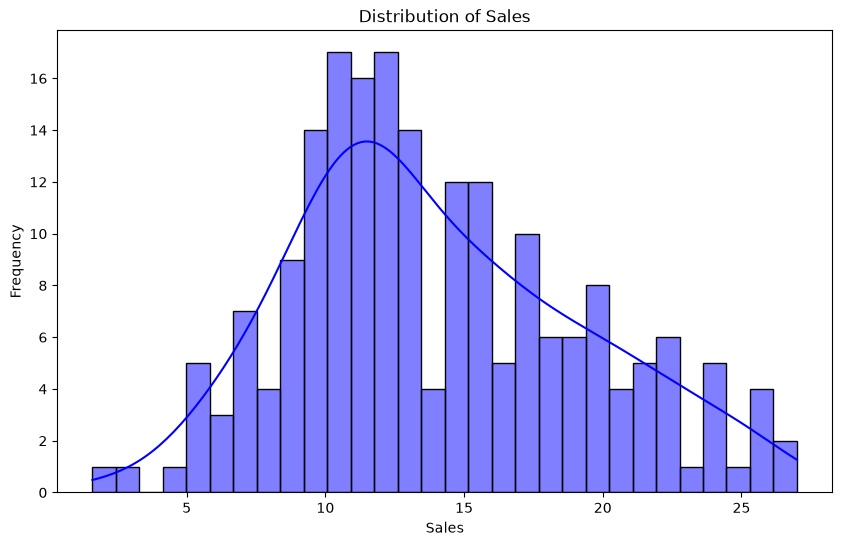

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Sales'], bins=30, kde=True, color='blue')
plt.title('Distribution of Sales')
plt.xlabel('Sales')
plt.ylabel('Frequency')
plt.show()

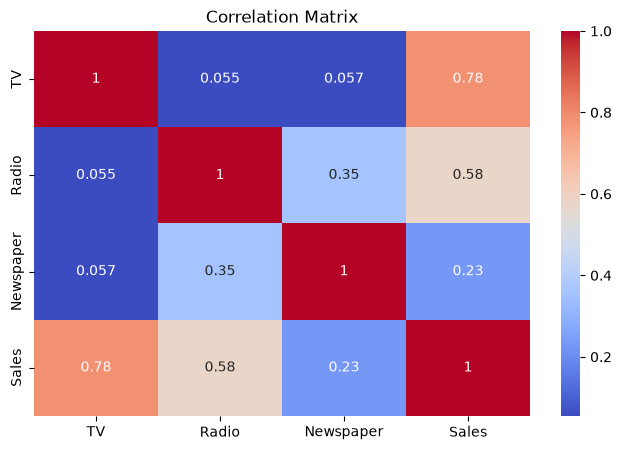

In [28]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

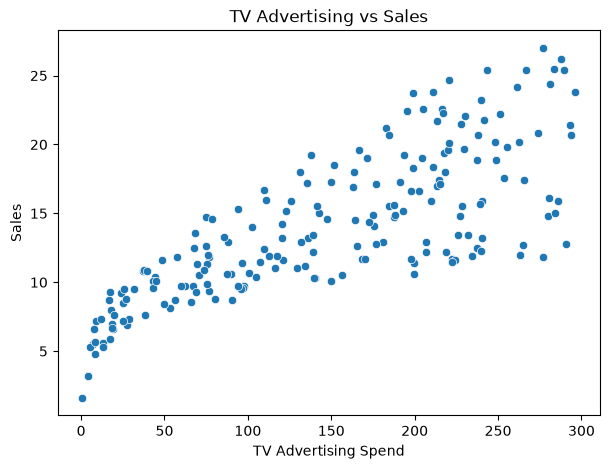

In [29]:
# STEP 7: TV Advertising vs Sales
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df,x="TV",y="Sales")

plt.title("TV Advertising vs Sales")
plt.xlabel("TV Advertising Spend")
plt.ylabel("Sales")
plt.show()

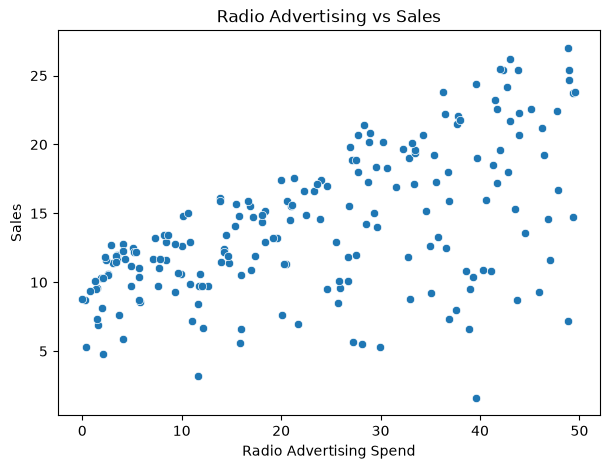

In [30]:
# Radio Advertising vs Sales
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df,x="Radio",y="Sales")

plt.title("Radio Advertising vs Sales")
plt.xlabel("Radio Advertising Spend")
plt.ylabel("Sales")
plt.show()

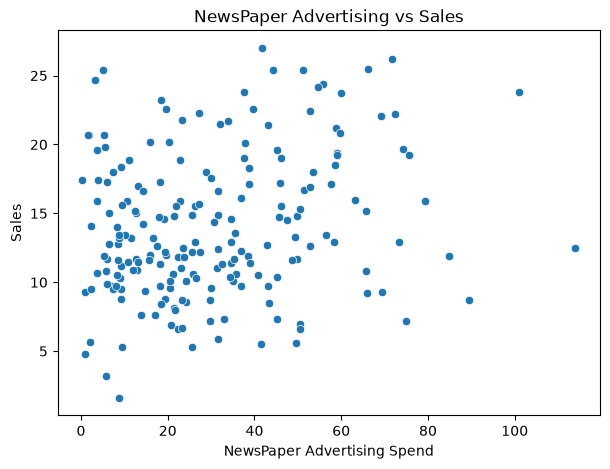

In [31]:
# NewsPaper Advertising vs Sales
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df,x="Newspaper",y="Sales")
plt.title("NewsPaper Advertising vs Sales")
plt.xlabel("NewsPaper Advertising Spend")
plt.ylabel("Sales")
plt.show()

In [32]:
# Step 8: Analye Advertising impact
print("TV correlation:", df["TV"].corr(df["Sales"]))
print("Radio correlation:", df["Radio"].corr(df["Sales"]))
print("Newspaper correlation:", df["Newspaper"].corr(df["Sales"]))

TV correlation: 0.7822244248616066
Radio correlation: 0.5762225745710553
Newspaper correlation: 0.22829902637616534


In [33]:
# step-9 : Define Features and Target
X = df[['TV', 'Radio', 'Newspaper']]
y = df['Sales']

In [34]:
# step -10: Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [35]:
# step 11 : Create the Linear Regression Model
model = LinearRegression()

In [36]:
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.04,0.19,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.979
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [37]:
print(X.head())

      TV  Radio  Newspaper
0  230.1   37.8       69.2
1   44.5   39.3       45.1
2   17.2   45.9       69.3
3  151.5   41.3       58.5
4  180.8   10.8       58.4


In [38]:
# step 12 :Make Predictions

y_pred = model.predict(X_test)

In [39]:
print(y_pred)

[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967  9.04831992  6.65328312
 14.34554487  8.90349333  9.68959028 12.16494386  8.73628397 16.26507258
 10.27759582 18.83109103 19.56036653 13.25103464 12.33620695 21.30695132
  7.82740305  5.80957448 20.75753231 11.98138077  9.18349576  8.5066991
 12.46646769 10.00337695 21.3876709  12.24966368 18.26661538 20.13766267
 14.05514005 20.85411186 11.0174441   4.56899622]


In [40]:
# step 13: Evaluate the Model
r2 = r2_score(y_test, y_pred)
print("R-squared:", r2)

R-squared: 0.899438024100912


In [41]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 1.78159966153345


In [42]:
# root mean squared error
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 1.78159966153345


In [43]:
# step-14 : Analyze Model Coefficients
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print(coefficients)

     Feature  Coefficient
0         TV     0.044730
1      Radio     0.189195
2  Newspaper     0.002761


In [44]:
print("In")

In


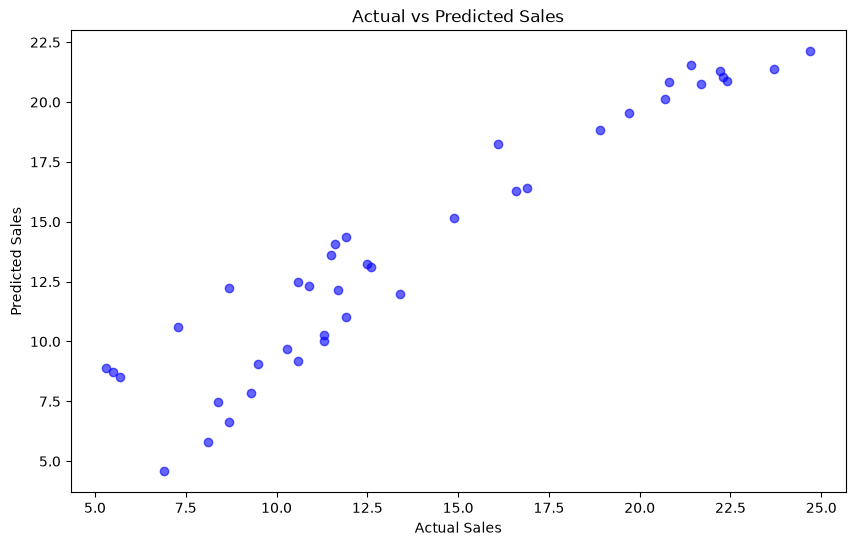

In [45]:
# step- 15: Visualize Actual vs Predicted Sales
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")
plt.show()

In [46]:
# step-16 : Check Residuals
residuals = y_test - y_pred

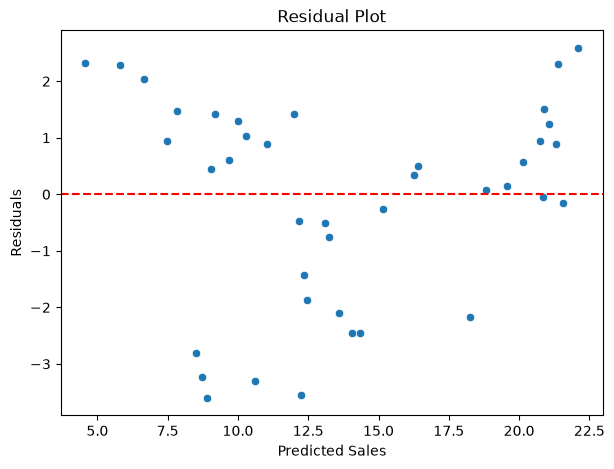

In [47]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals
)

plt.axhline(0, linestyle="--", color='red')

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [48]:
# step-17: Predict Sales for New Advertising Budget
new_data = pd.DataFrame({
    'TV': [150],
    'Radio': [30],
    'Newspaper': [20]
})
predicted_sales = model.predict(new_data)
print("Predicted Sales for new advertising budget:", predicted_sales[0])

Predicted Sales for new advertising budget: 15.419568872288718


In [49]:
# step -18 : Analyze "What If" Advertising Changes
scenarios = pd.DataFrame({
    "TV": [100, 150, 200, 250, 300],
    "Radio": [40, 40, 40, 40, 40],
    "Newspaper": [30, 30, 30, 30, 30]
})

scenarios["Predicted Sales"] = model.predict(
    scenarios[["TV", "Radio", "Newspaper"]]
)

print(scenarios)

    TV  Radio  Newspaper  Predicted Sales
0  100     40         30        15.102655
1  150     40         30        17.339131
2  200     40         30        19.575606
3  250     40         30        21.812082
4  300     40         30        24.048558


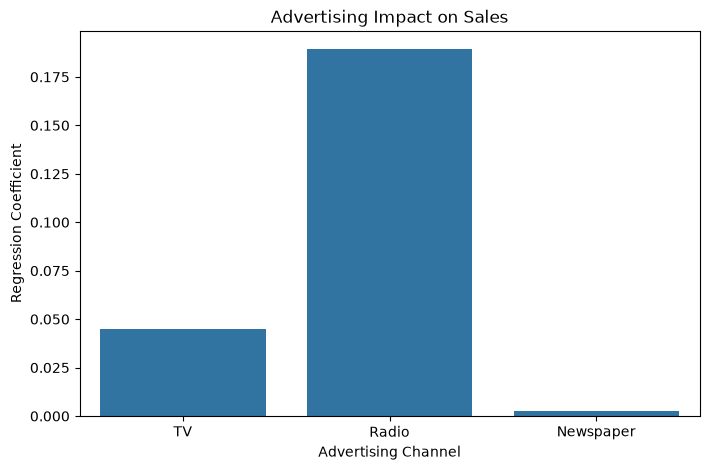

In [50]:
# step-19 : Create Advertising Impact Visualization
plt.figure(figsize=(8, 5))

sns.barplot(
    data=coefficients,
    x="Feature",
    y="Coefficient"
)

plt.title("Advertising Impact on Sales")
plt.xlabel("Advertising Channel")
plt.ylabel("Regression Coefficient")

plt.show()